# Kemiskinan dan Pengangguran di Indonesia
## Analisis Data 38 Provinsi, 2020–2025

**Proyek portofolio analisis data** · Sumber: Badan Pusat Statistik (BPS) · Dibuat: Oktober 2026

---

### Ringkasan satu menit

Indonesia berhasil menurunkan kemiskinan dari **9,78%** (Maret 2020) menjadi **8,47%** (Maret 2025),
dan Tingkat Pengangguran Terbuka (TPT) dari **7,07%** menjadi **4,85%** (Agustus 2020 → Agustus 2025).

Namun penurunan itu tidak merata. Pada 2025, kemiskinan antarprovinsi berkisar dari
**3,72% (Bali)** sampai **30,03% (Papua Pegunungan)** — sekitar **8 kali lipat**.

Yang lebih menarik: kemiskinan dan pengangguran **tidak bergerak searah** (korelasi -0,20).
Provinsi dengan pengangguran tinggi (Jawa Barat, Banten, Kepulauan Riau, DKI Jakarta)
justru memiliki kemiskinan rendah. Sebaliknya, kemiskinan tinggi terkonsentrasi di
Indonesia timur yang pengangguran terbukanya rendah. Artinya, **kemiskinan dan
pengangguran adalah dua masalah berbeda dan butuh strategi berbeda.**

> **Cara membaca notebook ini:** setiap bagian dijelaskan dengan bahasa sederhana.
> Istilah teknis diberi penjelasan singkat saat pertama muncul. Semua grafik punya
> judul, label sumbu, dan satu kalimat *insight* (temuan utama).

## 1. Pendahuluan

### 1.1 Latar belakang

Kemiskinan dan pengangguran adalah dua indikator yang paling sering dipakai untuk menilai
kesejahteraan suatu daerah. Keduanya sering dianggap saling terkait: jika orang tidak punya
pekerjaan, pendapatannya hilang, lalu ia jatuh miskin. Anggapan ini masuk akal, tetapi
**belum tentu benar di tingkat provinsi**. Notebook ini menguji anggapan tersebut dengan data resmi.

### 1.2 Pertanyaan yang ingin dijawab

1. Bagaimana tren kemiskinan dan pengangguran nasional pada 2020–2025?
2. Provinsi mana yang paling miskin dan mana yang penganggurannya paling tinggi pada 2025?
3. Provinsi mana yang paling cepat membaik dan mana yang justru memburuk selama 5 tahun?
4. Apakah kemiskinan dan pengangguran berkorelasi di tingkat provinsi?
5. Jika provinsi dikelompokkan berdasarkan dua indikator ini, kelompok seperti apa yang muncul?

### 1.3 Sumber data

| Indikator | Sumber | Periode | Satuan |
|---|---|---|---|
| Persentase penduduk miskin | BPS, *Jumlah dan Persentase Penduduk Miskin Menurut Provinsi* | Maret 2020–2025 (+ September 2024–2025) | % penduduk |
| Tingkat Pengangguran Terbuka (TPT) | BPS, *Tingkat Pengangguran Terbuka Menurut Provinsi* | Agustus 2020–2025 | % angkatan kerja |

- Tabel kemiskinan: <https://www.bps.go.id/id/statistics-table/3/UkVkWGJVZFNWakl6VWxKVFQwWjVWeTlSZDNabVFUMDkjMw%3D%3D/>
- Tabel TPT: <https://www.bps.go.id/id/statistics-table/3/V2pOVWJWcHJURGg0U2pONFJYaExhVXB0TUhacVFUMDkjMyMwMDAw/>
- Tanggal akses: 22 Oktober 2026.

> **Penting:** semua angka di notebook ini adalah angka resmi BPS, bukan data sintetis.
> File mentah disimpan di `data/raw/`, data bersih di `data/processed/`.

### 1.4 Istilah yang perlu diketahui

> - **Persentase penduduk miskin** — bagian penduduk yang pengeluaran per kapita per bulannya
>   di bawah garis kemiskinan. Contoh: 8,47% berarti 8–9 dari 100 orang miskin.
> - **TPT (Tingkat Pengangguran Terbuka)** — bagian angkatan kerja yang sedang mencari kerja,
>   menyiapkan usaha, atau sudah diterima kerja tetapi belum mulai bekerja. Orang yang bekerja
>   paruh waktu atau informal **tetap dihitung bekerja**, sehingga TPT bisa rendah walaupun
>   pekerjaannya tidak layak.
> - **Poin persentase (pp)** — selisih dua angka persen. Dari 9,78% ke 8,47% turun 1,31 pp
>   (bukan 1,31%). Ini cara yang benar untuk menyebut perubahan persentase.
> - **Korelasi (r)** — angka -1 sampai +1 yang menunjukkan seberapa searah dua variabel.
>   Mendekati +1 = naik bersama; mendekati -1 = satu naik, yang lain turun; 0 = tidak ada pola lurus.
> - **K-Means** — algoritma pengelompokan yang membagi data menjadi *k* kelompok berdasarkan kemiripan.

## 2. Import library dan pengaturan

**Library** adalah kumpulan kode siap pakai. Yang kita butuhkan:

- `pandas` — mengolah tabel data.
- `numpy` — hitungan matematika.
- `matplotlib` & `seaborn` — grafik statis.
- `plotly` — grafik interaktif (bisa di-zoom dan di-hover).
- `scikit-learn` — K-Means dan penskalaan data.

In [1]:
# 2. Import library dan pengaturan dasar

import json
import logging
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

warnings.filterwarnings("ignore", category=FutureWarning)

# --- Lokasi folder -----------------------------------------------------------
# Notebook ini ada di dalam folder "notebooks", sedangkan data ada di folder induk.
BASE_DIR = Path.cwd()
if BASE_DIR.name == "notebooks":
    BASE_DIR = BASE_DIR.parent

DATA_RAW = BASE_DIR / "data" / "raw"
DATA_PROCESSED = BASE_DIR / "data" / "processed"
GEOJSON = BASE_DIR / "data" / "geojson" / "indonesia_provinces.geojson"
IMAGES = BASE_DIR / "images"
IMAGES.mkdir(parents=True, exist_ok=True)
DATA_PROCESSED.mkdir(parents=True, exist_ok=True)

# --- Gaya grafik -------------------------------------------------------------
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.titlesize"] = 13
plt.rcParams["axes.titleweight"] = "bold"
plt.rcParams["axes.labelsize"] = 10

BIRU = "#1f4e79"
MERAH = "#c0392b"
HIJAU = "#2e7d32"
ORANGE = "#e67e22"
ABU = "#7f8c8d"

# Plotly ditampilkan sebagai gambar agar tetap terlihat di GitHub.
# Saat menjalankan notebook di komputer sendiri, ganti ke "notebook" atau "browser"
# untuk mendapatkan grafik interaktif.
pio.renderers.default = "png"


def simpan(fig, nama_file, insight):
    # Simpan grafik matplotlib ke folder images/ dan tambahkan kalimat insight.
    # Posisi insight dihitung dari batas bawah gambar agar tidak menabrak label sumbu.
    fig.canvas.draw()
    kotak = fig.get_tightbbox(fig.canvas.get_renderer())
    y_insight = kotak.y0 / fig.get_figheight() - 0.03
    fig.text(
        0.01, y_insight, "Insight: " + insight,
        fontsize=9, style="italic", color="#333333", ha="left", va="top",
    )
    fig.savefig(IMAGES / nama_file, dpi=150, bbox_inches="tight", facecolor="white")
    plt.show()


def tampilkan_plotly(fig, nama_file):
    # Tampilkan grafik Plotly lalu simpan sebagai PNG.
    # Pesan teknis dari mesin render (kaleido) disembunyikan agar output notebook bersih.
    logging.disable(logging.CRITICAL)
    try:
        fig.show()
        fig.write_image(IMAGES / nama_file, scale=2)
        print("Grafik disimpan ke images/" + nama_file)
    except Exception as e:
        print("Grafik tampil, tetapi gagal disimpan sebagai gambar:", e)
    finally:
        logging.disable(logging.NOTSET)


print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("matplotlib  :", plt.matplotlib.__version__)
print("seaborn     :", sns.__version__)
print("plotly      :", plotly.__version__)
print("scikit-learn:", __import__("sklearn").__version__)
print("\nFolder kerja:", BASE_DIR)

pandas      : 3.0.6
numpy       : 2.5.4
matplotlib  : 3.11.2
seaborn     : 0.13.2
plotly      : 7.1.0
scikit-learn: 1.9.1

Folder kerja: C:\DA_file\Voicehub\indonesia-poverty-unemployment-analysis


## 3. Memuat data dan pemeriksaan awal

Kita punya tiga file mentah:

| File | Isi |
|---|---|
| `kemiskinan_bps_2020_2025.csv` | kemiskinan per provinsi per tahun (Maret dan September) |
| `tpt_bps_2020_2025.csv` | TPT per provinsi per tahun (Agustus) |
| `nasional_bps_2020_2025.csv` | angka nasional untuk pembanding |

Pemeriksaan awal penting dilakukan supaya kita tahu **kondisi data sebelum diolah**:
berapa baris, tipe datanya apa, ada nilai kosong atau duplikat atau tidak.

In [2]:
# 3. Memuat data dan pemeriksaan awal

miskin_raw = pd.read_csv(DATA_RAW / "kemiskinan_bps_2020_2025.csv")
tpt_raw = pd.read_csv(DATA_RAW / "tpt_bps_2020_2025.csv")
nasional = pd.read_csv(DATA_RAW / "nasional_bps_2020_2025.csv")

print("Ukuran data:")
print(f"  kemiskinan : {miskin_raw.shape[0]} baris x {miskin_raw.shape[1]} kolom")
print(f"  TPT        : {tpt_raw.shape[0]} baris x {tpt_raw.shape[1]} kolom")
print(f"  nasional   : {nasional.shape[0]} baris x {nasional.shape[1]} kolom")

print("\n--- 5 baris pertama: kemiskinan ---")
display(miskin_raw.head())

print("--- 5 baris pertama: TPT (perhatikan nama provinsinya) ---")
display(tpt_raw.head())

print("--- Data nasional ---")
display(nasional)

Ukuran data:
  kemiskinan : 212 baris x 4 kolom
  TPT        : 212 baris x 3 kolom
  nasional   : 6 baris x 4 kolom

--- 5 baris pertama: kemiskinan ---


,provinsi,tahun,kemiskinan_maret,kemiskinan_september
0,Aceh,2020,14.99,NaN
1,Sumatera Utara,2020,8.75,NaN
2,Sumatera Barat,2020,6.28,NaN
3,Riau,2020,6.82,NaN
4,Jambi,2020,7.58,NaN


--- 5 baris pertama: TPT (perhatikan nama provinsinya) ---


,PROVINSI,TAHUN,TPT_AGUSTUS
0,ACEH,2020,6.59
1,SUMATERA UTARA,2020,6.91
2,SUMATERA BARAT,2020,6.88
3,RIAU,2020,6.32
4,JAMBI,2020,5.13


--- Data nasional ---


,tahun,kemiskinan_maret,kemiskinan_september,tpt_agustus
0,2020,9.78,NaN,7.07
1,2021,10.14,NaN,6.49
2,2022,9.54,NaN,5.86
3,2023,9.36,NaN,5.32
4,2024,9.03,8.57,4.91
5,2025,8.47,8.25,4.85


In [3]:
# Tipe data, nilai kosong, dan duplikat

print("=== Tipe data kemiskinan ===")
print(miskin_raw.dtypes)
print("\n=== Tipe data TPT ===")
print(tpt_raw.dtypes)

print("\n=== Nilai kosong per kolom ===")
print("Kemiskinan:")
print(miskin_raw.isna().sum())
print("\nTPT:")
print(tpt_raw.isna().sum())

print("\n=== Duplikat provinsi + tahun ===")
print("Kemiskinan:", miskin_raw.duplicated(["provinsi", "tahun"]).sum())
print("TPT       :", tpt_raw.duplicated(["PROVINSI", "TAHUN"]).sum())

=== Tipe data kemiskinan ===
provinsi                    str
tahun                     int64
kemiskinan_maret        float64
kemiskinan_september    float64
dtype: object

=== Tipe data TPT ===
PROVINSI           str
TAHUN            int64
TPT_AGUSTUS    float64
dtype: object

=== Nilai kosong per kolom ===
Kemiskinan:
provinsi                  0
tahun                     0
kemiskinan_maret          0
kemiskinan_september    136
dtype: int64

TPT:
PROVINSI       0
TAHUN          0
TPT_AGUSTUS    0
dtype: int64

=== Duplikat provinsi + tahun ===
Kemiskinan: 0
TPT       : 0


In [4]:
# Cakupan provinsi per tahun dan nilai ekstrem

print("Jumlah provinsi unik per tahun (kemiskinan):")
print(miskin_raw.groupby("tahun")["provinsi"].nunique())

print("\nJumlah provinsi unik per tahun (TPT):")
print(tpt_raw.groupby("TAHUN")["PROVINSI"].nunique())

print("\nRentang nilai:")
print("  kemiskinan Maret     :", miskin_raw.kemiskinan_maret.min(), "-", miskin_raw.kemiskinan_maret.max(), "%")
print("  TPT Agustus          :", tpt_raw.TPT_AGUSTUS.min(), "-", tpt_raw.TPT_AGUSTUS.max(), "%")

print("\nContoh nama provinsi di file TPT (belum seragam):")
print(sorted(tpt_raw["PROVINSI"].unique())[:9])

Jumlah provinsi unik per tahun (kemiskinan):
tahun
2020    34
2021    34
2022    34
2023    34
2024    38
2025    38
Name: provinsi, dtype: int64

Jumlah provinsi unik per tahun (TPT):
TAHUN
2020    34
2021    34
2022    34
2023    34
2024    38
2025    38
Name: PROVINSI, dtype: int64

Rentang nilai:
  kemiskinan Maret     : 3.72 - 32.97 %
  TPT Agustus          : 1.32 - 10.95 %

Contoh nama provinsi di file TPT (belum seragam):
['ACEH', 'BALI', 'BANTEN', 'BENGKULU', 'DI YOGYAKARTA', 'DKI JAKARTA', 'GORONTALO', 'JAMBI', 'JAWA BARAT']


### Temuan pemeriksaan awal

- Ada **212 baris** di tiap file. 34 provinsi × 4 tahun (2020–2023) + 38 provinsi × 2 tahun (2024–2025) = 212. ✅
- **Tidak ada duplikat** provinsi–tahun. ✅
- **Tidak ada kemiskinan Maret atau TPT yang kosong.** Nilai kosong hanya ada di kolom
  kemiskinan September (136 sel), karena BPS baru menerbitkan angka September untuk 2024 dan 2025.
- **Jumlah provinsi berubah** dari 34 (2020–2023) menjadi 38 (2024–2025). Penyebabnya:
  empat provinsi baru di Papua (Papua Selatan, Papua Tengah, Papua Pegunungan, Papua Barat Daya)
  resmi dibentuk pada 2022 dan datanya mulai tersedia pada 2024.
- **Nama provinsi di file TPT belum seragam** (`DKI JAKARTA`, `KEP. RIAU`, dan lain-lain),
  sedangkan file kemiskinan memakai huruf kapital di awal kata. Ini akan kita rapikan di bagian 4.

> **Catatan analis:** perubahan jumlah provinsi adalah hal yang harus selalu dicek.
> Kalau tidak, kita bisa membandingkan 34 provinsi pada 2020 dengan 38 provinsi pada 2025
> lalu menyimpulkan penurunan yang sebenarnya hanya efek bertambahnya wilayah.

## 4. Pembersihan data

Ada dua pekerjaan:

1. **Menyeragamkan nama provinsi** agar dua file bisa digabung. Contoh: `KEP. RIAU` → `Kepulauan Riau`,
   `DKI JAKARTA` → `DKI Jakarta`.
2. **Menggabungkan** data kemiskinan dan TPT menjadi satu tabel (*panel*) dengan kunci
   `provinsi` + `tahun`.

> **Apa itu panel?** Tabel yang berisi banyak daerah dan banyak tahun sekaligus.
> Dengan format ini, satu baris = satu provinsi pada satu tahun.

In [5]:
# 4a. Menyeragamkan nama provinsi

def bersihkan_nama(nama):
    # Mengubah nama provinsi BPS menjadi format baku yang dipakai di proyek ini.
    nama = nama.strip().title()                    # "JAWA BARAT" -> "Jawa Barat"
    nama = nama.replace("Kep.", "Kepulauan")       # "Kep. Riau"  -> "Kepulauan Riau"
    perbaikan = {
        "Dki Jakarta": "DKI Jakarta",              # singkatan resmi tetap huruf besar
        "Di Yogyakarta": "DI Yogyakarta",
    }
    return perbaikan.get(nama, nama)


tpt = tpt_raw.copy()
tpt["provinsi"] = tpt["PROVINSI"].map(bersihkan_nama)
miskin = miskin_raw.copy()

print("Sebelum dibersihkan :", tpt_raw["PROVINSI"].iloc[5], "|", tpt_raw["PROVINSI"].iloc[11])
print("Sesudah dibersihkan :", tpt["provinsi"].iloc[5], "|", tpt["provinsi"].iloc[11])

# Pastikan nama di kedua file benar-benar sama
nama_kemiskinan = set(miskin["provinsi"])
nama_tpt = set(tpt["provinsi"])
print("\nNama ada di kemiskinan, tidak ada di TPT:", sorted(nama_kemiskinan - nama_tpt))
print("Nama ada di TPT, tidak ada di kemiskinan:", sorted(nama_tpt - nama_kemiskinan))

Sebelum dibersihkan : SUMATERA SELATAN | JAWA BARAT
Sesudah dibersihkan : Sumatera Selatan | Jawa Barat

Nama ada di kemiskinan, tidak ada di TPT: []
Nama ada di TPT, tidak ada di kemiskinan: []


In [6]:
# 4b. Menggabungkan menjadi satu tabel panel

tpt = tpt.rename(columns={"TAHUN": "tahun", "TPT_AGUSTUS": "tpt"})
tpt = tpt[["provinsi", "tahun", "tpt"]]

panel = miskin.merge(
    tpt,
    on=["provinsi", "tahun"],
    how="inner",
    validate="one_to_one",   # gagal jika ada baris ganda; pengaman kualitas data
)
panel = panel.sort_values(["provinsi", "tahun"]).reset_index(drop=True)

print("Baris hasil gabungan :", len(panel))
print("Provinsi unik        :", panel["provinsi"].nunique())
print("Tahun                :", sorted(panel["tahun"].unique()))

print("\nJumlah baris per tahun:")
print(panel.groupby("tahun").size())

print("\nNilai kosong per kolom:")
print(panel.isna().sum())

Baris hasil gabungan : 212
Provinsi unik        : 38
Tahun                : [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]

Jumlah baris per tahun:
tahun
2020    34
2021    34
2022    34
2023    34
2024    38
2025    38
dtype: int64

Nilai kosong per kolom:
provinsi                  0
tahun                     0
kemiskinan_maret          0
kemiskinan_september    136
tpt                       0
dtype: int64


In [7]:
# 4c. Menyimpan data bersih

output = DATA_PROCESSED / "panel_kemiskinan_pengangguran_2020_2025.csv"
panel.to_csv(output, index=False)

print("Data bersih disimpan ke:", output.relative_to(BASE_DIR))
print("\nContoh isi data bersih:")
display(panel.head(8))
display(panel.tail(8))

Data bersih disimpan ke: data\processed\panel_kemiskinan_pengangguran_2020_2025.csv

Contoh isi data bersih:


,provinsi,tahun,kemiskinan_maret,kemiskinan_september,tpt
0,Aceh,2020,14.99,NaN,6.59
1,Aceh,2021,15.33,NaN,6.30
2,Aceh,2022,14.64,NaN,6.17
3,Aceh,2023,14.45,NaN,6.03
4,Aceh,2024,14.23,12.64,5.75
5,Aceh,2025,12.33,12.22,5.64
6,Bali,2020,3.78,NaN,5.63
7,Bali,2021,4.53,NaN,5.37


,provinsi,tahun,kemiskinan_maret,kemiskinan_september,tpt
204,Sumatera Selatan,2024,10.97,10.51,3.86
205,Sumatera Selatan,2025,10.15,9.85,3.69
206,Sumatera Utara,2020,8.75,NaN,6.91
207,Sumatera Utara,2021,9.01,NaN,6.33
208,Sumatera Utara,2022,8.42,NaN,6.16
209,Sumatera Utara,2023,8.15,NaN,5.89
210,Sumatera Utara,2024,7.99,7.19,5.60
211,Sumatera Utara,2025,7.36,7.24,5.32


### Keputusan pembersihan yang perlu dijelaskan

- **Inner join** dipakai karena kita hanya menganalisis provinsi–tahun yang punya **kedua** indikator.
  Hasilnya tetap 212 baris: cakupan kedua file identik.
- **Empat provinsi baru Papua** hanya punya data 2024–2025. Mereka tetap dipakai untuk analisis
  lintas provinsi 2025, tetapi otomatis keluar saat menghitung perubahan 2020→2025 (karena tidak punya angka 2020).
- **Papua dan Papua Barat** punya data lengkap 2020–2025, **tetapi batas wilayahnya berubah**
  pada 2022 (sebagian wilayahnya menjadi provinsi baru). Akibatnya angka 2020 dan 2025 mengukur
  wilayah yang berbeda, sehingga keduanya **dikeluarkan dari peringkat perubahan**.
  Angka TPT Papua melonjak dari 2,67% (2023) ke 6,48% (2024) bukan karena pengangguran naik,
  melainkan karena wilayah yang dihitung berubah — ini contoh *perangkap data* yang umum.
- Setelah pengecualian itu, tersisa **34 provinsi** dengan seri lengkap, dan **32 provinsi**
  yang layak dibandingkan perubahannya.

> **Kesimpulan bagian ini:** data bersih siap dipakai, dengan 38 provinsi untuk analisis 2025
> dan 32 provinsi untuk analisis perubahan 2020→2025.

## 5. Analisis data eksploratif (EDA)

**EDA** (*exploratory data analysis*) adalah langkah melihat ringkasan dan sebaran data
sebelum menarik kesimpulan. Kita mulai dari statistik deskriptif, lalu grafik sebaran.

In [8]:
# 5a. Statistik deskriptif dan peringkat 2025

terbaru = panel[panel["tahun"] == 2025].copy()

print("=== Statistik deskriptif 38 provinsi, 2025 ===")
display(terbaru[["kemiskinan_maret", "kemiskinan_september", "tpt"]].describe().round(2))

print("\n=== 5 provinsi termiskin (Maret 2025) ===")
display(
    terbaru.nlargest(5, "kemiskinan_maret")[["provinsi", "kemiskinan_maret", "tpt"]]
    .rename(columns={"kemiskinan_maret": "miskin (%)", "tpt": "TPT (%)"})
)

print("=== 5 provinsi dengan kemiskinan terendah (Maret 2025) ===")
display(
    terbaru.nsmallest(5, "kemiskinan_maret")[["provinsi", "kemiskinan_maret", "tpt"]]
    .rename(columns={"kemiskinan_maret": "miskin (%)", "tpt": "TPT (%)"})
)

print("=== 5 provinsi dengan TPT tertinggi (Agustus 2025) ===")
display(
    terbaru.nlargest(5, "tpt")[["provinsi", "kemiskinan_maret", "tpt"]]
    .rename(columns={"kemiskinan_maret": "miskin (%)", "tpt": "TPT (%)"})
)

=== Statistik deskriptif 38 provinsi, 2025 ===


,kemiskinan_maret,kemiskinan_september,tpt
count,38.00,38.00,38.00
mean,10.61,10.27,4.47
std,6.55,6.27,1.38
min,3.72,3.42,1.49
25%,5.68,5.53,3.50
50%,9.49,9.35,4.21
75%,12.27,12.14,5.54
max,30.03,29.45,6.96



=== 5 provinsi termiskin (Maret 2025) ===


,provinsi,miskin (%),TPT (%)
153,Papua Pegunungan,30.03,1.68
157,Papua Tengah,28.90,3.62
149,Papua Barat,20.66,4.55
155,Papua Selatan,19.71,4.04
143,Papua,19.16,6.96


=== 5 provinsi dengan kemiskinan terendah (Maret 2025) ===


,provinsi,miskin (%),TPT (%)
11,Bali,3.72,1.49
77,Kalimantan Selatan,3.84,4.16
35,DKI Jakarta,4.28,6.05
107,Kepulauan Riau,4.44,6.45
101,Kepulauan Bangka Belitung,5.00,4.45


=== 5 provinsi dengan TPT tertinggi (Agustus 2025) ===


,provinsi,miskin (%),TPT (%)
143,Papua,19.16,6.96
151,Papua Barat Daya,17.95,6.85
53,Jawa Barat,7.02,6.77
17,Banten,5.63,6.69
107,Kepulauan Riau,4.44,6.45


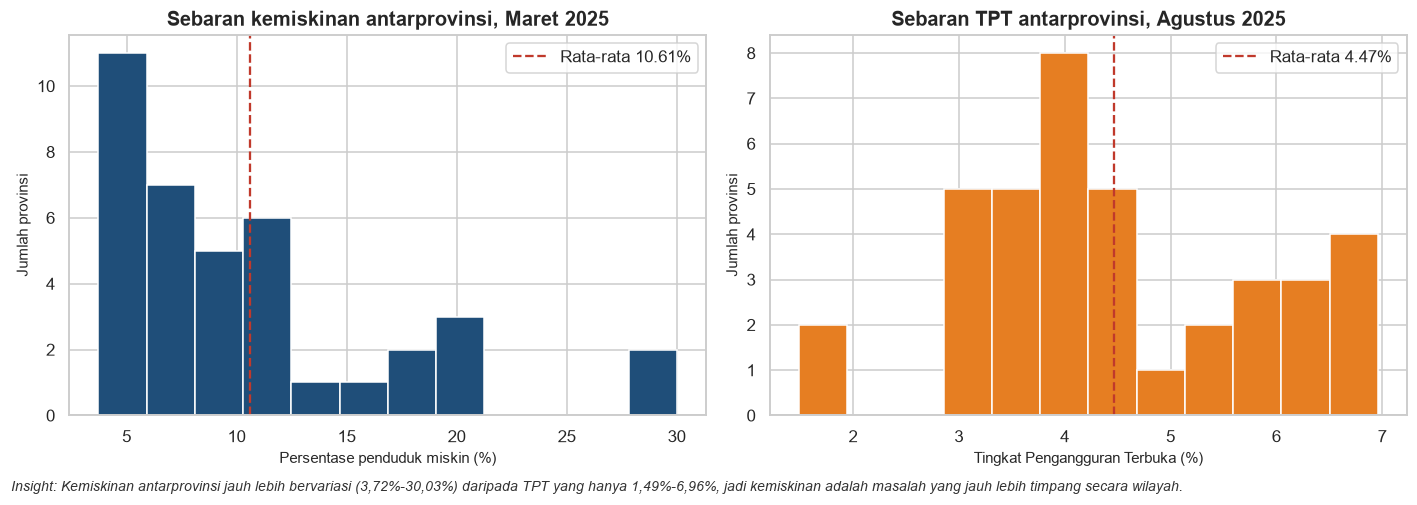

In [9]:
# 5b. Sebaran kemiskinan dan TPT antarprovinsi

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(terbaru["kemiskinan_maret"], bins=12, color=BIRU, edgecolor="white")
axes[0].axvline(
    terbaru["kemiskinan_maret"].mean(), color=MERAH, linestyle="--", linewidth=1.5,
    label=f"Rata-rata {terbaru['kemiskinan_maret'].mean():.2f}%",
)
axes[0].set_title("Sebaran kemiskinan antarprovinsi, Maret 2025")
axes[0].set_xlabel("Persentase penduduk miskin (%)")
axes[0].set_ylabel("Jumlah provinsi")
axes[0].legend()

axes[1].hist(terbaru["tpt"], bins=12, color=ORANGE, edgecolor="white")
axes[1].axvline(
    terbaru["tpt"].mean(), color=MERAH, linestyle="--", linewidth=1.5,
    label=f"Rata-rata {terbaru['tpt'].mean():.2f}%",
)
axes[1].set_title("Sebaran TPT antarprovinsi, Agustus 2025")
axes[1].set_xlabel("Tingkat Pengangguran Terbuka (%)")
axes[1].set_ylabel("Jumlah provinsi")
axes[1].legend()

fig.tight_layout()
simpan(
    fig, "02_distribusi_2025.png",
    "Kemiskinan antarprovinsi jauh lebih bervariasi (3,72%-30,03%) daripada TPT yang hanya 1,49%-6,96%, "
    "jadi kemiskinan adalah masalah yang jauh lebih timpang secara wilayah.",
)

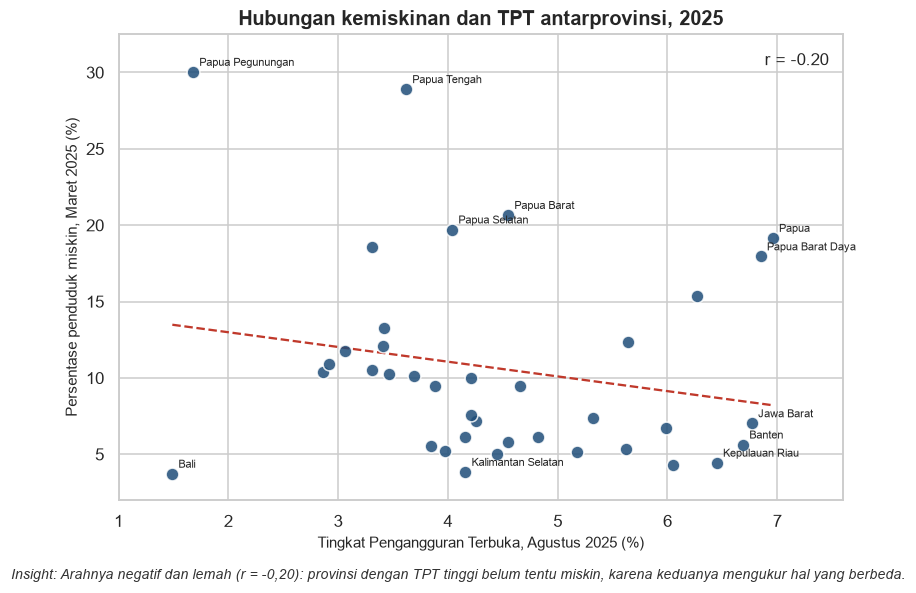

In [10]:
# 5c. Hubungan sederhana: kemiskinan vs TPT (2025)

fig, ax = plt.subplots(figsize=(8.5, 5.5))
ax.scatter(
    terbaru["tpt"], terbaru["kemiskinan_maret"],
    s=70, color=BIRU, alpha=0.85, edgecolor="white", zorder=3,
)

# Garis tren linear (hanya alat bantu visual, bukan prediksi)
m, c = np.polyfit(terbaru["tpt"], terbaru["kemiskinan_maret"], 1)
x_garis = np.linspace(terbaru["tpt"].min(), terbaru["tpt"].max(), 100)
ax.plot(x_garis, m * x_garis + c, color=MERAH, linestyle="--", linewidth=1.5, zorder=2)

# Beri label hanya pada titik ekstrem agar grafik tidak penuh tulisan
for _, row in terbaru.iterrows():
    if row["kemiskinan_maret"] > 19 or row["tpt"] > 6.4 or row["kemiskinan_maret"] < 4:
        ax.annotate(
            row["provinsi"], (row["tpt"], row["kemiskinan_maret"]),
            fontsize=7.5, xytext=(4, 4), textcoords="offset points",
        )

r = terbaru["kemiskinan_maret"].corr(terbaru["tpt"])
ax.set_title("Hubungan kemiskinan dan TPT antarprovinsi, 2025")
ax.set_xlabel("Tingkat Pengangguran Terbuka, Agustus 2025 (%)")
ax.set_ylabel("Persentase penduduk miskin, Maret 2025 (%)")
ax.set_xlim(1.0, 7.6)
ax.set_ylim(2.0, 32.5)
ax.text(0.98, 0.96, f"r = {r:.2f}", transform=ax.transAxes, fontsize=11,
        va="top", ha="right")

simpan(
    fig, "03_scatter_kemiskinan_tpt.png",
    "Arahnya negatif dan lemah (r = -0,20): provinsi dengan TPT tinggi belum tentu miskin, "
    "karena keduanya mengukur hal yang berbeda.",
)

### Yang terlihat di bagian 5

- Rata-rata kemiskinan 38 provinsi **10,61%**, tetapi mediannya lebih rendah (**9,49%**).
  Artinya sebarannya *miring ke kanan*: sebagian besar provinsi di bawah 12%, dan segelintir
  provinsi di Papua sangat tinggi sehingga menarik rata-rata ke atas.
- Sebaran TPT jauh lebih sempit (standar deviasi 1,38 vs 6,55 untuk kemiskinan).
  Hampir semua provinsi berada di antara 3% dan 7%.
- **Di luar enam provinsi Papua**, sepuluh provinsi dengan kemiskinan tertinggi adalah NTT (18,60%),
  Maluku (15,38%), Gorontalo (13,24%), Aceh (12,33%), Bengkulu (12,08%), NTB (11,78%),
  Sulawesi Tengah (10,92%), Sulawesi Tenggara (10,54%), Sulawesi Barat (10,41%),
  dan DI Yogyakarta (10,23%). Hampir semuanya berada di Indonesia timur, ditambah tiga
  provinsi di Sumatera (Aceh, Bengkulu, dan Sumatera Selatan).
- **TPT tertinggi** justru berada di provinsi yang relatif kaya: Papua (6,96%),
  Papua Barat Daya (6,85%), Jawa Barat (6,77%), Banten (6,69%), Kepulauan Riau (6,45%),
  dan DKI Jakarta (6,05%).
- **TPT terendah** ada di Bali (1,49%), Papua Pegunungan (1,68%), Sulawesi Barat (2,86%),
  dan Sulawesi Tengah (2,92%) — tiga di antaranya justru termasuk provinsi termiskin.

> **Apa artinya?** Di provinsi miskin, orang **bekerja** — tetapi sering di sektor informal
> atau sebagai pekerja keluarga dengan penghasilan rendah. Mereka tidak masuk hitungan
> "penganggur terbuka", tetapi tetap miskin. Inilah sebabnya dua indikator ini bisa bergerak
> berlawanan arah.

## 6. Analisis perubahan 2020–2025

Sekarang kita hitung **selisih** setiap provinsi antara 2020 dan 2025, bukan hanya nilainya.
Tujuannya menjawab: siapa yang benar-benar membaik, dan siapa yang tertinggal?

> **Kenapa memakai selisih (delta), bukan persentase perubahan?**
> Keduanya sah, tetapi untuk indikator yang sudah berbentuk persen, selisih dalam
> **poin persentase** lebih mudah ditafsirkan. Contoh: 15,03% → 12,08% = turun **2,95 pp**.

In [11]:
# 6a. Menghitung perubahan tiap provinsi

kemiskinan_lebar = panel.pivot_table(index="provinsi", columns="tahun", values="kemiskinan_maret")
tpt_lebar = panel.pivot_table(index="provinsi", columns="tahun", values="tpt")

perubahan = pd.DataFrame({
    "provinsi": kemiskinan_lebar.index,
    "kemiskinan_2020": kemiskinan_lebar[2020].values,
    "kemiskinan_2025": kemiskinan_lebar[2025].values,
    "tpt_2020": tpt_lebar[2020].values,
    "tpt_2025": tpt_lebar[2025].values,
}).dropna().reset_index(drop=True)

perubahan["delta_kemiskinan"] = perubahan["kemiskinan_2025"] - perubahan["kemiskinan_2020"]
perubahan["delta_tpt"] = perubahan["tpt_2025"] - perubahan["tpt_2020"]

print("Provinsi dengan data lengkap 2020-2025:", len(perubahan))

# Papua & Papua Barat tidak sebanding karena wilayahnya dimekarkan pada 2022
tidak_sebanding = ["Papua", "Papua Barat"]
banding = perubahan[~perubahan["provinsi"].isin(tidak_sebanding)].copy()

print("Provinsi yang dipakai untuk peringkat perubahan:", len(banding))
print()
print("Kemiskinan turun:", (banding["delta_kemiskinan"] < 0).sum(), "provinsi")
print("Kemiskinan naik :", (banding["delta_kemiskinan"] > 0).sum(), "provinsi")
print("TPT turun       :", (banding["delta_tpt"] < 0).sum(), "provinsi")
print("TPT naik        :", (banding["delta_tpt"] > 0).sum(), "provinsi")

Provinsi dengan data lengkap 2020-2025: 34
Provinsi yang dipakai untuk peringkat perubahan: 32

Kemiskinan turun: 30 provinsi
Kemiskinan naik : 2 provinsi
TPT turun       : 32 provinsi
TPT naik        : 0 provinsi


In [12]:
# 6b. Tabel perubahan, diurutkan dari penurunan kemiskinan terbesar

tabel_perubahan = banding[[
    "kemiskinan_2020", "kemiskinan_2025", "delta_kemiskinan",
    "tpt_2020", "tpt_2025", "delta_tpt",
]].sort_values("delta_kemiskinan")

display(
    tabel_perubahan.round(2).rename(columns={
        "kemiskinan_2020": "miskin 2020 (%)",
        "kemiskinan_2025": "miskin 2025 (%)",
        "delta_kemiskinan": "Δ miskin (pp)",
        "tpt_2020": "TPT 2020 (%)",
        "tpt_2025": "TPT 2025 (%)",
        "delta_tpt": "Δ TPT (pp)",
    })
)

,miskin 2020 (%),miskin 2025 (%),Δ miskin (pp),TPT 2020 (%),TPT 2025 (%),Δ TPT (pp)
3,15.03,12.08,-2.95,4.07,3.41,-0.66
0,14.99,12.33,-2.66,6.59,5.64,-0.95
32,12.66,10.15,-2.51,5.51,3.69,-1.82
18,12.34,10.00,-2.34,4.67,4.21,-0.46
22,20.90,18.60,-2.30,4.28,3.31,-0.97
21,13.97,11.78,-2.19,4.22,3.06,-1.16
19,17.44,15.38,-2.06,7.57,6.27,-1.30
4,12.28,10.23,-2.05,4.57,3.46,-1.11
28,12.92,10.92,-2.00,3.77,2.92,-0.85
6,15.22,13.24,-1.98,4.28,3.42,-0.86


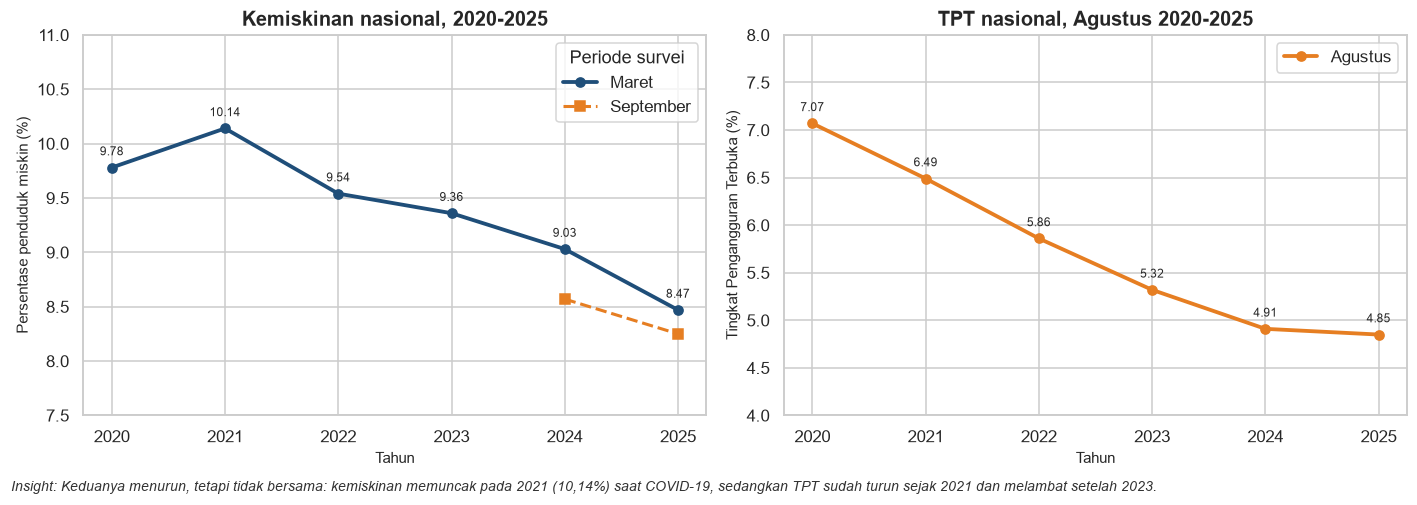

In [13]:
# 6c. Grafik tren nasional

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# --- Kemiskinan ---
axes[0].plot(
    nasional["tahun"], nasional["kemiskinan_maret"],
    marker="o", linewidth=2.5, color=BIRU, label="Maret",
)
sept = nasional.dropna(subset=["kemiskinan_september"])
axes[0].plot(
    sept["tahun"], sept["kemiskinan_september"],
    marker="s", linewidth=2, linestyle="--", color=ORANGE, label="September",
)
for x, y in zip(nasional["tahun"], nasional["kemiskinan_maret"]):
    axes[0].annotate(f"{y:.2f}", (x, y), textcoords="offset points", xytext=(0, 8),
                     ha="center", fontsize=8)
axes[0].set_title("Kemiskinan nasional, 2020-2025")
axes[0].set_xlabel("Tahun")
axes[0].set_ylabel("Persentase penduduk miskin (%)")
axes[0].set_ylim(7.5, 11)
axes[0].set_xticks(nasional["tahun"])
axes[0].legend(title="Periode survei")

# --- TPT ---
axes[1].plot(
    nasional["tahun"], nasional["tpt_agustus"],
    marker="o", linewidth=2.5, color=ORANGE, label="Agustus",
)
for x, y in zip(nasional["tahun"], nasional["tpt_agustus"]):
    axes[1].annotate(f"{y:.2f}", (x, y), textcoords="offset points", xytext=(0, 8),
                     ha="center", fontsize=8)
axes[1].set_title("TPT nasional, Agustus 2020-2025")
axes[1].set_xlabel("Tahun")
axes[1].set_ylabel("Tingkat Pengangguran Terbuka (%)")
axes[1].set_ylim(4, 8)
axes[1].set_xticks(nasional["tahun"])
axes[1].legend()

fig.tight_layout()
simpan(
    fig, "01_tren_nasional.png",
    "Keduanya menurun, tetapi tidak bersama: kemiskinan memuncak pada 2021 (10,14%) saat COVID-19, "
    "sedangkan TPT sudah turun sejak 2021 dan melambat setelah 2023.",
)

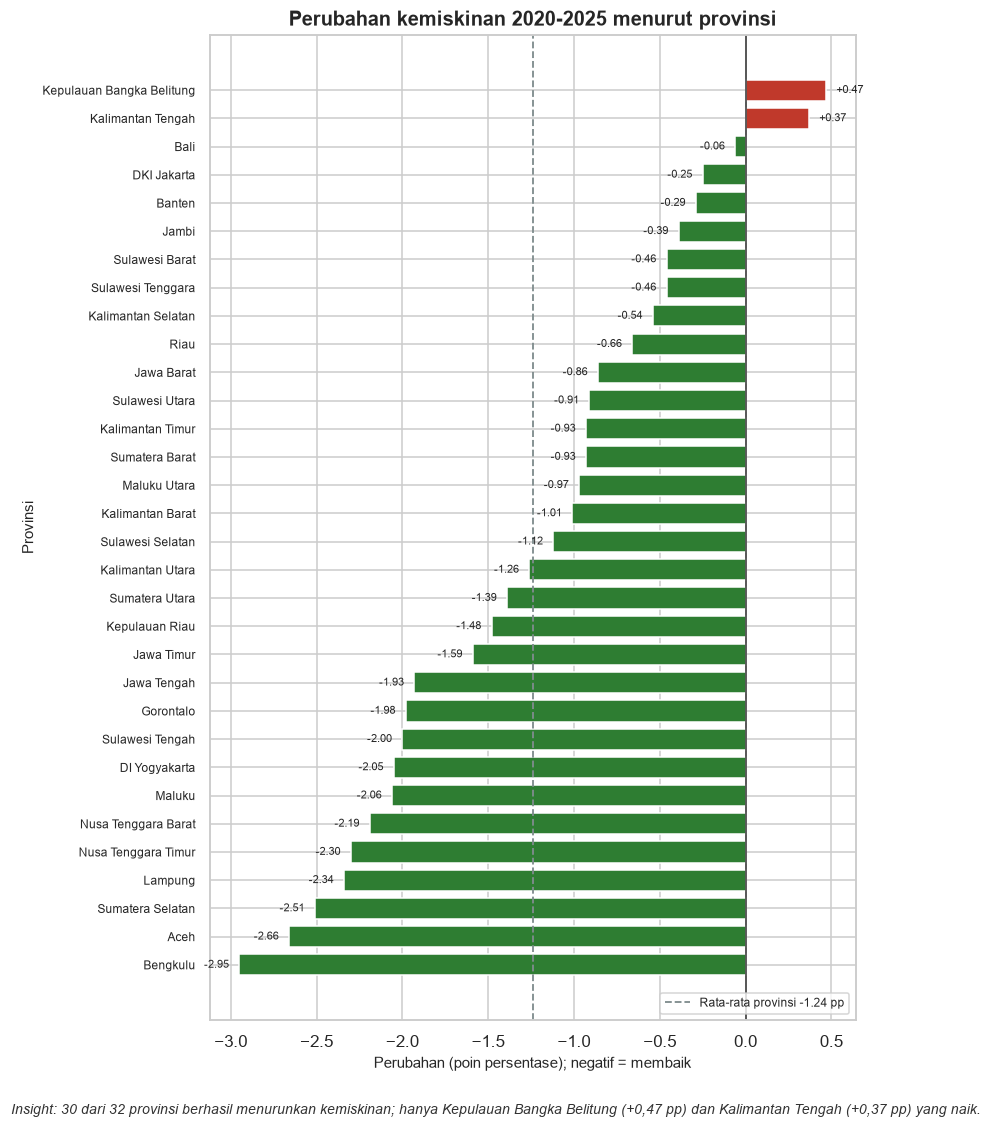

In [14]:
# 6d. Grafik batang: perubahan kemiskinan tiap provinsi

urut = banding.sort_values("delta_kemiskinan").set_index("provinsi")
warna = [MERAH if v > 0 else HIJAU for v in urut["delta_kemiskinan"]]

fig, ax = plt.subplots(figsize=(8, 10))
ax.barh(urut.index, urut["delta_kemiskinan"], color=warna, height=0.75)
ax.axvline(0, color="#333333", linewidth=1)
ax.axvline(
    urut["delta_kemiskinan"].mean(), color=ABU, linestyle="--", linewidth=1.2,
    label=f"Rata-rata provinsi {urut['delta_kemiskinan'].mean():.2f} pp",
)

for i, (nama, nilai) in enumerate(urut["delta_kemiskinan"].items()):
    ax.text(nilai - 0.06 if nilai < 0 else nilai + 0.06, i, f"{nilai:+.2f}",
            va="center", ha="right" if nilai < 0 else "left", fontsize=7)

ax.set_title("Perubahan kemiskinan 2020-2025 menurut provinsi")
ax.set_xlabel("Perubahan (poin persentase); negatif = membaik")
ax.set_ylabel("Provinsi")
ax.tick_params(axis="y", labelsize=8)
ax.legend(loc="lower right", fontsize=8)

fig.tight_layout()
simpan(
    fig, "04_perubahan_kemiskinan.png",
    "30 dari 32 provinsi berhasil menurunkan kemiskinan; hanya Kepulauan Bangka Belitung (+0,47 pp) "
    "dan Kalimantan Tengah (+0,37 pp) yang naik.",
)

### Temuan bagian 6

**Nasional**

- Kemiskinan Maret: **9,78% → 8,47%** (turun **1,31 pp**) dan merupakan angka terendah dalam seri 2020–2025.
- Kemiskinan memuncak pada **2021 (10,14%)**, saat dampak pandemi paling terasa; sejak itu turun konsisten.
- TPT Agustus: **7,07% → 4,85%** (turun **2,22 pp**), penurunan lebih besar daripada kemiskinan.
- Kemiskinan September 2025 (**8,25%**) lebih rendah daripada Maret 2025 (**8,47%**), dan
  **35 dari 38** provinsi juga mencatat angka September lebih rendah. Pola ini konsisten
  dengan faktor **musiman**: kemiskinan biasanya sedikit lebih tinggi pada Maret.

**Antarprovinsi (32 provinsi yang sebanding)**

- **30 provinsi menurunkan kemiskinan**, hanya **2 naik**: Kepulauan Bangka Belitung (+0,47 pp)
  dan Kalimantan Tengah (+0,37 pp).
- Penurunan terbesar: **Bengkulu -2,95 pp**, **Aceh -2,66 pp**, **Sumatera Selatan -2,51 pp**,
  **Lampung -2,34 pp**, **NTT -2,30 pp**.
- **Seluruh 32 provinsi menurunkan TPT.** Penurunan terbesar di **DKI Jakarta (-4,90 pp)**,
  **Bali (-4,14 pp)**, **Banten (-3,95 pp)**, **Kepulauan Riau (-3,89 pp)**, **Jawa Barat (-3,69 pp)**.
- Rata-rata provinsi turun **1,24 pp** untuk kemiskinan dan **1,62 pp** untuk TPT.

> **Penting:** penurunan TPT terbesar terjadi di provinsi yang TPT-nya paling tinggi pada 2020.
> Ini disebut *mean reversion* — angka yang ekstrem cenderung kembali ke rata-rata.
> Sebagian besar perbaikan TPT sebenarnya terjadi pada 2020→2022, saat ekonomi pulih dari COVID-19.

## 7. Analisis korelasi

**Korelasi** mengukur seberapa kuat dua variabel bergerak bersama.

- **Pearson** — mengukur hubungan *garis lurus*. Peka terhadap nilai ekstrem.
- **Spearman** — mengukur hubungan *peringkat* (urutan). Lebih tahan terhadap nilai ekstrem.

Kita pakai keduanya karena data kita punya beberapa provinsi dengan nilai sangat tinggi (Papua).

In [15]:
# 7a. Korelasi di beberapa potongan data

def korelasi(df, kolom_x, kolom_y, label):
    pearson = df[kolom_x].corr(df[kolom_y])
    spearman = df[kolom_x].corr(df[kolom_y], method="spearman")
    print(f"{label:<45} n={len(df):>2}  Pearson={pearson:+.3f}  Spearman={spearman:+.3f}")


data_2020 = panel[panel["tahun"] == 2020]
papua_6 = [
    "Papua", "Papua Barat", "Papua Barat Daya",
    "Papua Selatan", "Papua Tengah", "Papua Pegunungan",
]
terbaru_non_papua = terbaru[~terbaru["provinsi"].isin(papua_6)]

print("Korelasi kemiskinan vs TPT:")
korelasi(data_2020, "kemiskinan_maret", "tpt", "2020, 34 provinsi")
korelasi(terbaru, "kemiskinan_maret", "tpt", "2025, 38 provinsi")
korelasi(terbaru_non_papua, "kemiskinan_maret", "tpt", "2025, tanpa 6 provinsi Papua")
korelasi(banding, "delta_kemiskinan", "delta_tpt", "Perubahan 2020-2025, 32 provinsi")

Korelasi kemiskinan vs TPT:
2020, 34 provinsi                             n=34  Pearson=-0.342  Spearman=-0.371
2025, 38 provinsi                             n=38  Pearson=-0.203  Spearman=-0.234
2025, tanpa 6 provinsi Papua                  n=32  Pearson=-0.255  Spearman=-0.355
Perubahan 2020-2025, 32 provinsi              n=32  Pearson=-0.276  Spearman=-0.165


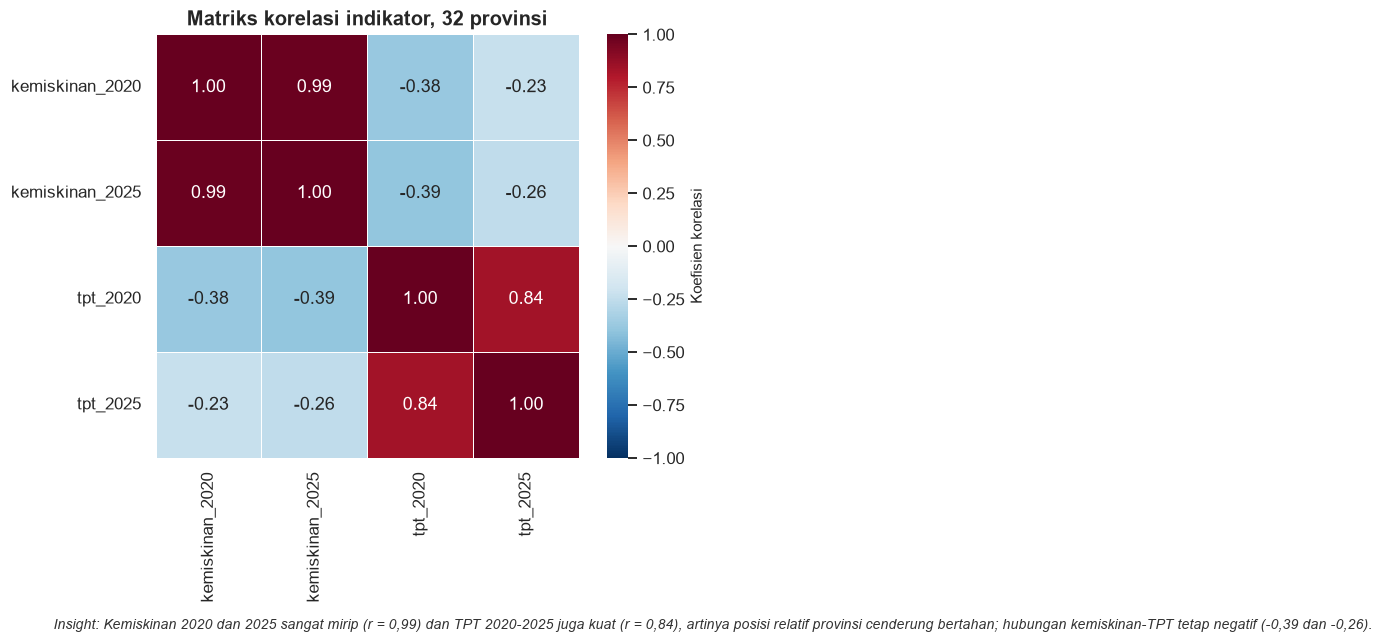

In [16]:
# 7b. Matriks korelasi empat indikator (32 provinsi sebanding)

matriks = banding[["kemiskinan_2020", "kemiskinan_2025", "tpt_2020", "tpt_2025"]].corr()

fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(
    matriks, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1,
    square=True, linewidths=0.6, ax=ax,
    cbar_kws={"label": "Koefisien korelasi"},
)
ax.set_title("Matriks korelasi indikator, 32 provinsi")
ax.set_xlabel("")
ax.set_ylabel("")

simpan(
    fig, "05_matriks_korelasi.png",
    "Kemiskinan 2020 dan 2025 sangat mirip (r = 0,99) dan TPT 2020-2025 juga kuat (r = 0,84), "
    "artinya posisi relatif provinsi cenderung bertahan; hubungan kemiskinan-TPT tetap negatif (-0,39 dan -0,26).",
)

### Cara membaca hasil korelasi

| Potongan data | Pearson | Spearman | Tafsiran |
|---|---|---|---|
| 2020, 34 provinsi | **-0,34** | -0,37 | negatif sedang |
| 2025, 38 provinsi | **-0,20** | -0,23 | negatif lemah |
| 2025, tanpa 6 provinsi Papua | **-0,26** | -0,36 | negatif lemah–sedang |
| Perubahan 2020→2025, 32 provinsi | **-0,28** | -0,17 | negatif lemah |

Tiga hal yang bisa disimpulkan:

1. **Arahnya konsisten negatif** di semua potongan data. Provinsi dengan TPT lebih tinggi
   cenderung punya kemiskinan lebih rendah — kebalikan dari dugaan umum.
2. **Kekuatannya lemah** (|r| < 0,4). Jadi TPT bukan prediktor yang baik untuk kemiskinan.
   Sebagian besar variasi kemiskinan dijelaskan hal lain: harga pangan, akses layanan dasar,
   geografi, dan struktur ekonomi.
3. **Korelasinya melemah** dari -0,34 (2020) ke -0,20 (2025). Setelah pandemi, hubungan
   dua indikator ini makin longgar.

> **Peringatan penting:** korelasi **bukan** kausalitas. Angka negatif ini tidak berarti
> "pengangguran menurunkan kemiskinan". Penjelasan yang lebih masuk akal adalah perbedaan
> struktur ekonomi: provinsi miskin didominasi pertanian dan pekerja informal (bekerja tetapi
> berpenghasilan rendah), sedangkan provinsi kaya punya pasar kerja formal yang lebih besar
> sehingga pengangguran terbuka lebih mudah terlihat dan tercatat.
>
> n = 32–38 juga tergolong **kecil**, jadi angka korelasi bisa berubah cukup banyak bila
> satu-dua provinsi ekstrem dihilangkan — seperti terlihat pada perbandingan dengan/tanpa Papua.

## 8. Clustering dengan K-Means

**Clustering** adalah pengelompokan otomatis: kita tidak menentukan label lebih dulu,
algoritma yang mencari kelompok provinsi yang mirip.

**K-Means** bekerja dengan cara:

1. Menentukan jumlah kelompok `k`.
2. Menempatkan `k` titik pusat (*centroid*) secara acak.
3. Setiap data dimasukkan ke centroid terdekat.
4. Centroid dipindahkan ke rata-rata anggotanya.
5. Langkah 3–4 diulang sampai stabil.

**Kenapa data harus di-*standardize* dulu?** Karena K-Means memakai jarak. Tanpa penskalaan,
kemiskinan (rentang 3–30) akan mendominasi TPT (rentang 1–7) hanya karena angkanya lebih besar.
`StandardScaler` mengubah setiap variabel menjadi skala yang setara (rata-rata 0, simpangan baku 1).

Kita mengelompokkan berdasarkan **kondisi 2025** (kemiskinan dan TPT), lalu memakai
angka perubahan hanya untuk menafsirkan hasilnya.

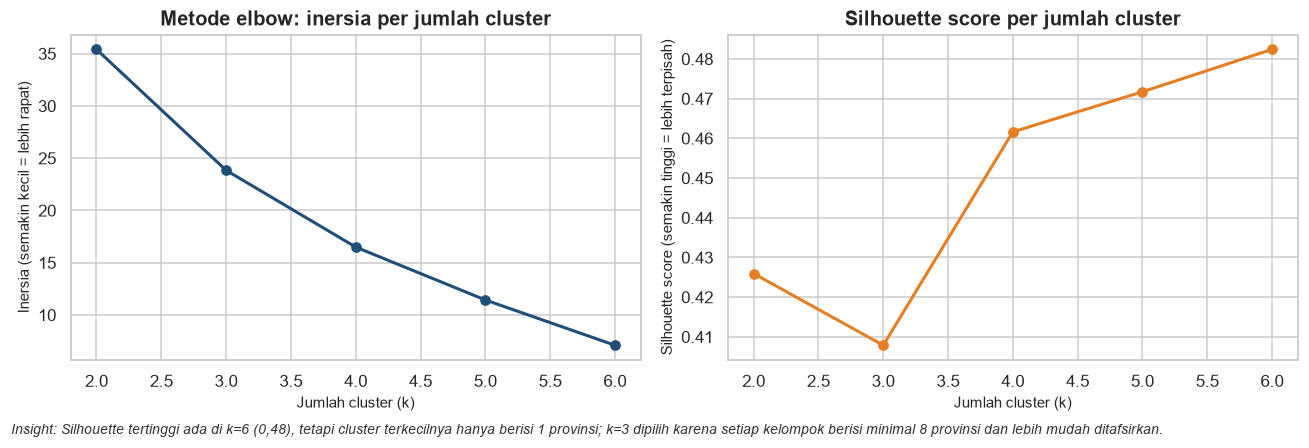

In [17]:
# 8a. Menentukan jumlah cluster yang wajar

fitur = banding[["kemiskinan_2025", "tpt_2025"]].copy()
scaler = StandardScaler()
X = scaler.fit_transform(fitur)

inersia, siluet = [], []
for k in range(2, 7):
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    label = km.fit_predict(X)
    inersia.append(km.inertia_)
    siluet.append(silhouette_score(X, label))

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(range(2, 7), inersia, marker="o", linewidth=2, color=BIRU)
axes[0].set_title("Metode elbow: inersia per jumlah cluster")
axes[0].set_xlabel("Jumlah cluster (k)")
axes[0].set_ylabel("Inersia (semakin kecil = lebih rapat)")

axes[1].plot(range(2, 7), siluet, marker="o", linewidth=2, color=ORANGE)
axes[1].set_title("Silhouette score per jumlah cluster")
axes[1].set_xlabel("Jumlah cluster (k)")
axes[1].set_ylabel("Silhouette score (semakin tinggi = lebih terpisah)")

fig.tight_layout()
simpan(
    fig, "06_elbow_silhouette.png",
    "Silhouette tertinggi ada di k=6 (0,48), tetapi cluster terkecilnya hanya berisi 1 provinsi; "
    "k=3 dipilih karena setiap kelompok berisi minimal 8 provinsi dan lebih mudah ditafsirkan.",
)

In [18]:
# 8b. Melatih model final dengan k=3

kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
banding["cluster"] = kmeans.fit_predict(X)

profil = banding.groupby("cluster").agg(
    jumlah=("provinsi", "size"),
    rata_kemiskinan=("kemiskinan_2025", "mean"),
    rata_tpt=("tpt_2025", "mean"),
    rata_delta_kemiskinan=("delta_kemiskinan", "mean"),
    rata_delta_tpt=("delta_tpt", "mean"),
).round(2)


def beri_nama(baris):
    # Memberi nama yang mudah dibaca berdasarkan ciri rata-rata cluster.
    if baris["rata_kemiskinan"] >= 9:
        return "Kemiskinan tinggi, TPT rendah"
    if baris["rata_tpt"] >= 5.3:
        return "Perkotaan/industri: TPT tinggi"
    return "Kemiskinan dan TPT rendah"


profil["nama"] = profil.apply(beri_nama, axis=1)
banding["nama_cluster"] = banding["cluster"].map(profil["nama"])

display(profil.rename(columns={
    "rata_kemiskinan": "rata-rata miskin 2025 (%)",
    "rata_tpt": "rata-rata TPT 2025 (%)",
    "rata_delta_kemiskinan": "rata-rata Δ miskin (pp)",
    "rata_delta_tpt": "rata-rata Δ TPT (pp)",
}))

print("Anggota tiap cluster:")
for c in sorted(banding["cluster"].unique()):
    anggota = sorted(banding.loc[banding["cluster"] == c, "provinsi"])
    print(f"\n[{profil.loc[c, 'nama']}] - {len(anggota)} provinsi")
    print("  " + ", ".join(anggota))

,jumlah,rata-rata miskin 2025 (%),rata-rata TPT 2025 (%),rata-rata Δ miskin (pp),rata-rata Δ TPT (pp),nama
cluster,,,,,,
0,8,5.74,6.01,-0.88,-2.79,Perkotaan/industri: TPT tinggi
1,14,11.76,3.86,-1.96,-1.12,"Kemiskinan tinggi, TPT rendah"
2,10,5.62,3.99,-0.52,-1.40,Kemiskinan dan TPT rendah


Anggota tiap cluster:

[Perkotaan/industri: TPT tinggi] - 8 provinsi
  Banten, DKI Jakarta, Jawa Barat, Kalimantan Timur, Kepulauan Riau, Sulawesi Utara, Sumatera Barat, Sumatera Utara

[Kemiskinan tinggi, TPT rendah] - 14 provinsi
  Aceh, Bengkulu, DI Yogyakarta, Gorontalo, Jawa Tengah, Jawa Timur, Lampung, Maluku, Nusa Tenggara Barat, Nusa Tenggara Timur, Sulawesi Barat, Sulawesi Tengah, Sulawesi Tenggara, Sumatera Selatan

[Kemiskinan dan TPT rendah] - 10 provinsi
  Bali, Jambi, Kalimantan Barat, Kalimantan Selatan, Kalimantan Tengah, Kalimantan Utara, Kepulauan Bangka Belitung, Maluku Utara, Riau, Sulawesi Selatan


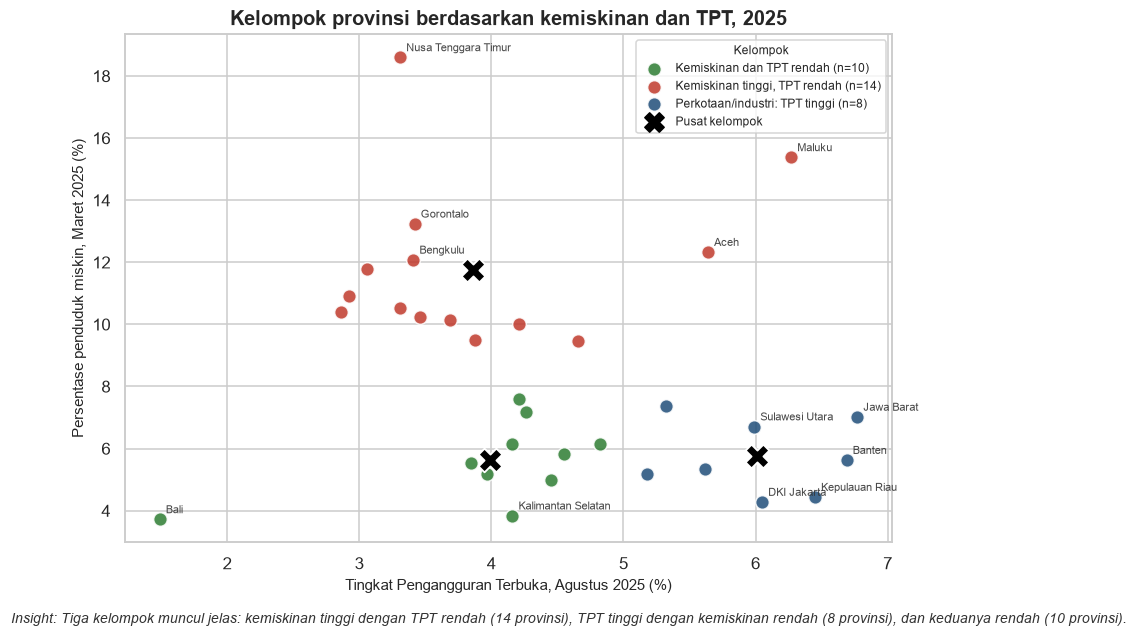

In [19]:
# 8c. Visualisasi cluster

warna_cluster = {
    "Kemiskinan tinggi, TPT rendah": MERAH,
    "Perkotaan/industri: TPT tinggi": BIRU,
    "Kemiskinan dan TPT rendah": HIJAU,
}

fig, ax = plt.subplots(figsize=(9, 6))

for nama, grup in banding.groupby("nama_cluster"):
    ax.scatter(
        grup["tpt_2025"], grup["kemiskinan_2025"],
        s=80, color=warna_cluster[nama], alpha=0.85,
        edgecolor="white", label=f"{nama} (n={len(grup)})", zorder=3,
    )

# Centroid dikembalikan ke satuan asli (%).
# Ingat: urutan kolom fitur adalah [kemiskinan, tpt], sedangkan sumbu grafik adalah [tpt, kemiskinan].
centroid = scaler.inverse_transform(kmeans.cluster_centers_)
for c_miskin, c_tpt in centroid:
    ax.scatter(c_tpt, c_miskin, marker="X", s=240, color="black",
               edgecolor="white", linewidth=1.2, zorder=5)

# Satu entri legenda untuk menjelaskan tanda X pada grafik
ax.scatter([], [], marker="X", s=160, color="black", label="Pusat kelompok")

# Label hanya provinsi yang menonjol agar grafik tidak penuh tulisan.
for _, row in banding.iterrows():
    if row["kemiskinan_2025"] > 12 or row["tpt_2025"] > 5.9 or row["kemiskinan_2025"] < 4.2:
        ax.annotate(
            row["provinsi"], (row["tpt_2025"], row["kemiskinan_2025"]),
            fontsize=7.5, color="#333333", alpha=0.9,
            xytext=(4, 4), textcoords="offset points",
        )

ax.set_title("Kelompok provinsi berdasarkan kemiskinan dan TPT, 2025")
ax.set_xlabel("Tingkat Pengangguran Terbuka, Agustus 2025 (%)")
ax.set_ylabel("Persentase penduduk miskin, Maret 2025 (%)")
ax.legend(title="Kelompok", loc="upper right", fontsize=8, title_fontsize=8)

simpan(
    fig, "07_cluster_provinsi.png",
    "Tiga kelompok muncul jelas: kemiskinan tinggi dengan TPT rendah (14 provinsi), "
    "TPT tinggi dengan kemiskinan rendah (8 provinsi), dan keduanya rendah (10 provinsi).",
)

### Tafsiran tiga cluster

| Kelompok | Jumlah | Rata-rata miskin | Rata-rata TPT | Ciri |
|---|---|---|---|---|
| Kemiskinan tinggi, TPT rendah | 14 | 11,76% | 3,86% | Aceh, Bengkulu, DIY, Gorontalo, Jateng, Jatim, Lampung, Maluku, NTB, NTT, Sulbar, Sulteng, Sultra, Sumsel |
| Perkotaan/industri: TPT tinggi | 8 | 5,75% | 6,01% | Banten, DKI Jakarta, Jabar, Kaltim, Kepri, Sulut, Sumbar, Sumut |
| Kemiskinan dan TPT rendah | 10 | 5,62% | 3,99% | Bali, Jambi, Kalbar, Kalsel, Kalteng, Kaltara, Babel, Malut, Riau, Sulsel |

Yang perlu diperhatikan:

- Kelompok **"kemiskinan tinggi, TPT rendah"** justru mencatat **penurunan kemiskinan terbesar**
  (rata-rata -2,21 pp). Jadi mereka bukan provinsi yang "tidak bergerak" — mereka adalah
  wilayah dengan tingkat kemiskinan awal tinggi yang sedang mengejar.
- Kelompok **"perkotaan/industri"** punya TPT tertinggi tetapi kemiskinan rendah.
  Di sini masalah utamanya adalah **kualitas dan ketersediaan lapangan kerja formal**,
  bukan daya beli.
- **Bali** adalah kasus khusus: TPT-nya turun paling dalam (-4,14 pp) karena sektor pariwisata
  pulih kuat setelah pandemi.
- Cluster ini **deskriptif, bukan diagnosis**. Nama kelompok adalah interpretasi penulis
  berdasarkan rata-rata, bukan label resmi BPS.

## 9. Visualisasi lanjutan

Bagian ini menyajikan data dalam bentuk yang lebih mudah dikomunikasikan:
*heatmap*, peta, dan grafik interaktif.

> Semua gambar juga disimpan otomatis ke folder `images/` agar bisa dipakai di README
> atau presentasi.

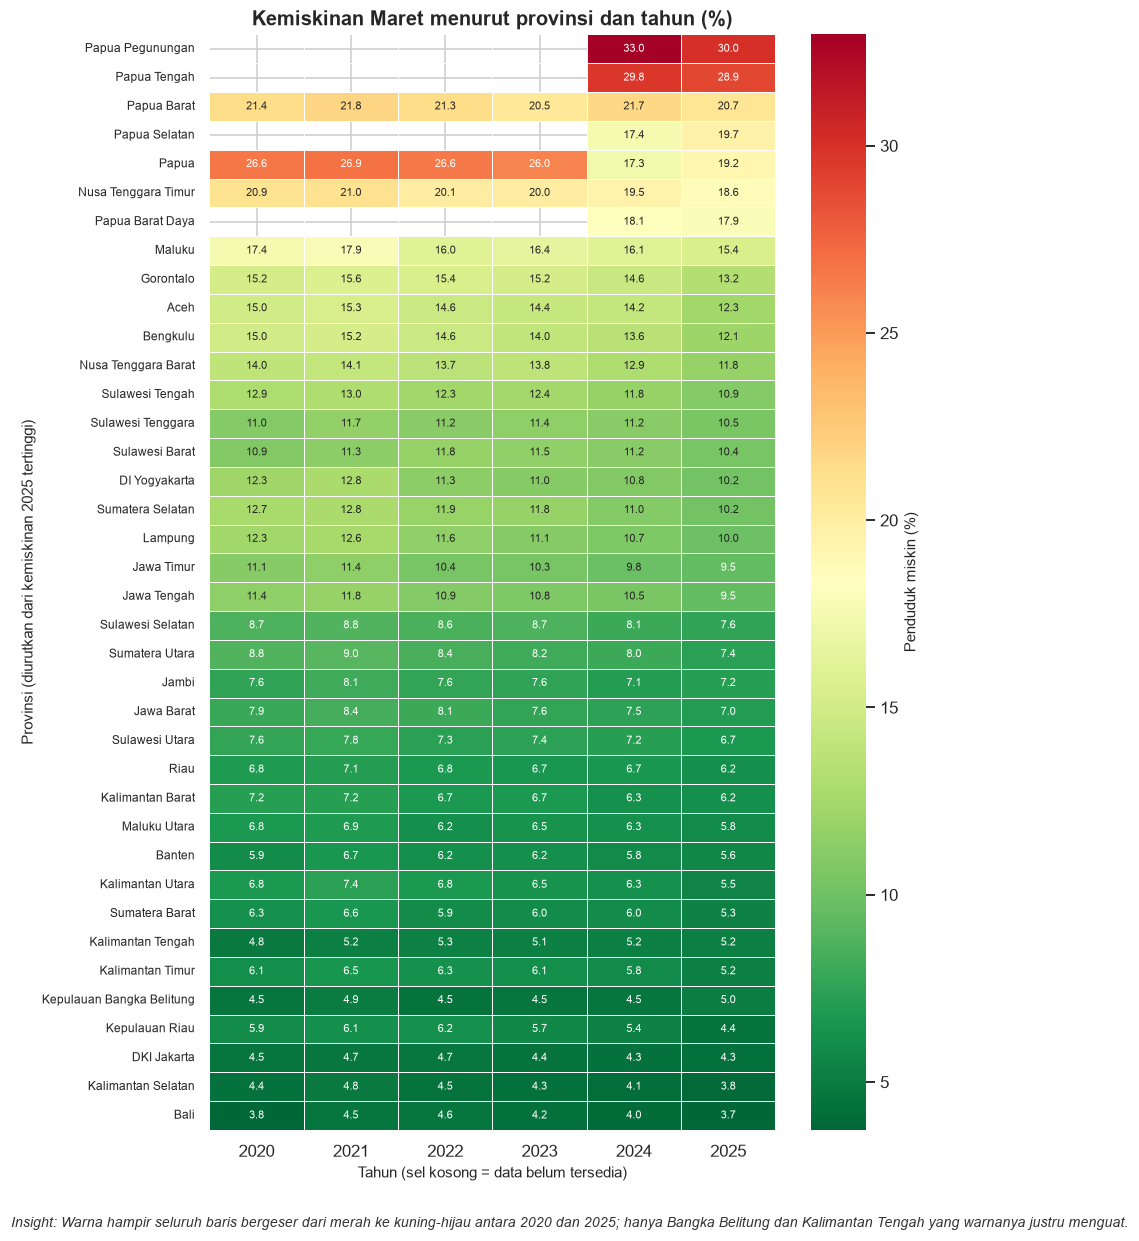

In [20]:
# 9a. Heatmap: kemiskinan semua provinsi x tahun

lebar_urut = kemiskinan_lebar.sort_values(2025, ascending=False)

fig, ax = plt.subplots(figsize=(8.5, 11))
sns.heatmap(
    lebar_urut, annot=True, fmt=".1f", cmap="RdYlGn_r",
    linewidths=0.5, ax=ax, annot_kws={"fontsize": 7},
    cbar_kws={"label": "Penduduk miskin (%)"},
)
ax.set_title("Kemiskinan Maret menurut provinsi dan tahun (%)")
ax.set_xlabel("Tahun (sel kosong = data belum tersedia)")
ax.set_ylabel("Provinsi (diurutkan dari kemiskinan 2025 tertinggi)")
ax.tick_params(axis="y", labelsize=8)

fig.tight_layout()
simpan(
    fig, "08_heatmap_kemiskinan.png",
    "Warna hampir seluruh baris bergeser dari merah ke kuning-hijau antara 2020 dan 2025; "
    "hanya Bangka Belitung dan Kalimantan Tengah yang warnanya justru menguat.",
)

Provinsi yang bisa digambar: 34 dari 38
Tidak ada di berkas peta: ['Papua Barat Daya', 'Papua Pegunungan', 'Papua Selatan', 'Papua Tengah']


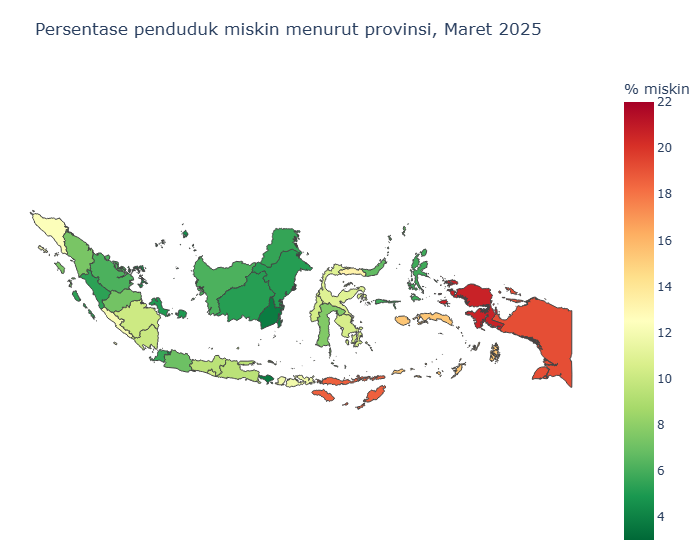

Grafik disimpan ke images/09_peta_kemiskinan.png


In [21]:
# 9b. Peta choropleth kemiskinan 2025

with open(GEOJSON, encoding="utf-8") as f:
    geojson = json.load(f)

# Nama provinsi di berkas peta berbeda untuk tiga provinsi
nama_peta = {
    "DI Yogyakarta": "Yogyakarta",
    "Kepulauan Bangka Belitung": "Bangka-Belitung",
    "DKI Jakarta": "Jakarta Raya",
}
peta = terbaru.copy()
peta["nama_peta"] = peta["provinsi"].replace(nama_peta)

nama_di_geojson = {f["properties"]["state"] for f in geojson["features"]}
peta = peta[peta["nama_peta"].isin(nama_di_geojson)].copy()

print("Provinsi yang bisa digambar:", len(peta), "dari", len(terbaru))
print("Tidak ada di berkas peta:", sorted(set(terbaru["provinsi"]) - set(peta["provinsi"])))

fig = px.choropleth(
    peta,
    geojson=geojson,
    locations="nama_peta",
    featureidkey="properties.state",
    color="kemiskinan_maret",
    color_continuous_scale="RdYlGn_r",
    range_color=(3, 22),
    hover_name="provinsi",
    hover_data={"kemiskinan_maret": ":.2f", "tpt": ":.2f", "nama_peta": False},
    labels={"kemiskinan_maret": "Penduduk miskin (%)"},
    title="Persentase penduduk miskin menurut provinsi, Maret 2025",
)
fig.update_geos(fitbounds="locations", visible=False)
fig.update_layout(
    height=560,
    margin=dict(l=0, r=0, t=70, b=10),
    coloraxis_colorbar=dict(title="% miskin"),
)
tampilkan_plotly(fig, "09_peta_kemiskinan.png")

> **Catatan peta:** berkas batas wilayah yang dipakai memuat **34 provinsi** (kondisi sebelum
> pemekaran Papua 2022). Empat provinsi baru (Papua Selatan, Papua Tengah, Papua Pegunungan,
> Papua Barat Daya) belum ada di berkas itu, sehingga tidak muncul di peta — tetapi tetap
> masuk di semua tabel dan grafik batang. Poligon "Papua" menampilkan angka Provinsi Papua saja.
>
> Skala warna diatur 3–22% mengikuti nilai provinsi yang tampil. Dua provinsi termiskin
> (Papua Pegunungan 30,03% dan Papua Tengah 28,90%) tidak tergambar, jadi warna tergelap
> di peta bukanlah nilai tertinggi di dataset.
>
> **Insight:** wilayah dengan kemiskinan tertinggi (warna oranye sampai merah) terkonsentrasi
> di Papua, Maluku, dan NTT, sedangkan Sumatera bagian selatan berwarna kuning dan Jawa bagian
> barat, Bali, serta Kalimantan berwarna hijau. Kemiskinan di Indonesia adalah fenomena
> **geografis**, bukan sekadar fenomena pasar kerja.

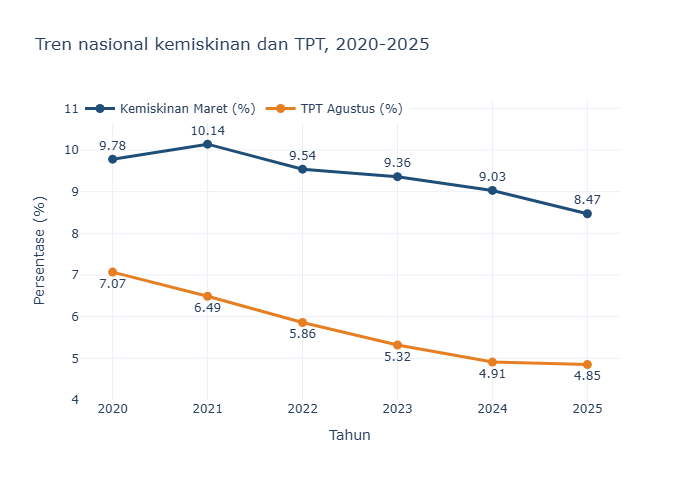

Grafik disimpan ke images/10_plotly_tren_nasional.png


In [22]:
# 9c. Grafik interaktif Plotly: tren nasional

fig = go.Figure()

fig.add_trace(go.Scatter(
    x=nasional["tahun"], y=nasional["kemiskinan_maret"],
    mode="lines+markers+text",
    text=[f"{v:.2f}" for v in nasional["kemiskinan_maret"]],
    textposition="top center",
    name="Kemiskinan Maret (%)",
    line=dict(color=BIRU, width=3),
    marker=dict(size=9),
    hovertemplate="Tahun %{x}<br>Kemiskinan: %{y:.2f}%<extra></extra>",
))

fig.add_trace(go.Scatter(
    x=nasional["tahun"], y=nasional["tpt_agustus"],
    mode="lines+markers+text",
    text=[f"{v:.2f}" for v in nasional["tpt_agustus"]],
    textposition="bottom center",
    name="TPT Agustus (%)",
    line=dict(color=ORANGE, width=3),
    marker=dict(size=9),
    hovertemplate="Tahun %{x}<br>TPT: %{y:.2f}%<extra></extra>",
))

fig.update_layout(
    title="Tren nasional kemiskinan dan TPT, 2020-2025",
    xaxis_title="Tahun",
    yaxis_title="Persentase (%)",
    yaxis=dict(range=[4, 11.2]),
    hovermode="x unified",
    legend=dict(orientation="h", y=1.02, x=0),
    template="plotly_white",
    height=480,
)
tampilkan_plotly(fig, "10_plotly_tren_nasional.png")

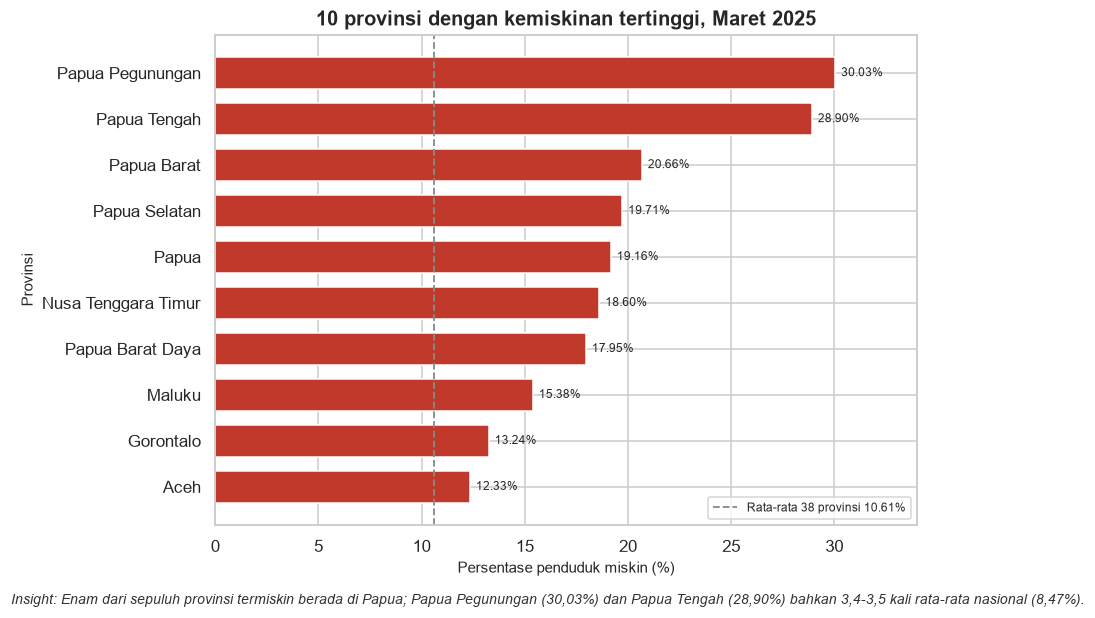

In [23]:
# 9d. Grafik batang: 10 provinsi termiskin 2025 (termasuk provinsi baru Papua)

top10 = terbaru.nlargest(10, "kemiskinan_maret").sort_values("kemiskinan_maret")

fig, ax = plt.subplots(figsize=(8.5, 5.5))
batang = ax.barh(top10["provinsi"], top10["kemiskinan_maret"], color=MERAH, height=0.7)

for bar, nilai in zip(batang, top10["kemiskinan_maret"]):
    ax.text(nilai + 0.3, bar.get_y() + bar.get_height() / 2, f"{nilai:.2f}%",
            va="center", fontsize=8)

ax.axvline(
    terbaru["kemiskinan_maret"].mean(), color=ABU, linestyle="--", linewidth=1.2,
    label=f"Rata-rata 38 provinsi {terbaru['kemiskinan_maret'].mean():.2f}%",
)
ax.set_xlim(0, 34)
ax.set_title("10 provinsi dengan kemiskinan tertinggi, Maret 2025")
ax.set_xlabel("Persentase penduduk miskin (%)")
ax.set_ylabel("Provinsi")
ax.legend(loc="lower right", fontsize=8)

fig.tight_layout()
simpan(
    fig, "11_top10_kemiskinan.png",
    "Enam dari sepuluh provinsi termiskin berada di Papua; Papua Pegunungan (30,03%) dan "
    "Papua Tengah (28,90%) bahkan 3,4-3,5 kali rata-rata nasional (8,47%).",
)

### Cara membaca visualisasi bagian 9

- **Heatmap** paling cocok untuk melihat **pola sekaligus**: kita bisa membandingkan satu provinsi
  lintas tahun (baris) dan satu tahun lintas provinsi (kolom) tanpa membuat 34 grafik.
- **Peta** menunjukkan **kedekatan geografis**: provinsi miskin cenderung berkelompok
  (Papua dan sekitarnya, Nusa Tenggara, Maluku, Sumatera bagian selatan), bukan tersebar acak.
- **Plotly** berguna saat presentasi karena angka muncul saat kursor diarahkan ke titik.
  Di GitHub grafik ini tampil sebagai gambar statis; versi interaktif muncul saat notebook
  dijalankan di komputer sendiri.

## 10. Kesimpulan dan rekomendasi

### 10.1 Kesimpulan

1. **Kemiskinan dan pengangguran sama-sama turun, tetapi dengan kecepatan berbeda.**
   Kemiskinan nasional turun 1,31 pp (9,78% → 8,47%) dan TPT turun 2,22 pp (7,07% → 4,85%)
   dalam lima tahun. Angka 2025 adalah yang terendah dalam seri.
2. **Pandemi terlihat jelas pada 2021.** Kemiskinan naik ke 10,14%, lalu turun setiap tahun.
   TPT justru memuncak pada 2020 (7,07%) karena survei Agustus 2020 menangkap guncangan awal.
3. **Ketimpangan wilayah tetap sangat besar.** Selisih provinsi termiskin dan terkaya mencapai
   26,31 pp (8 kali lipat). Sepuluh provinsi termiskin didominasi Indonesia timur.
4. **Hanya 2 dari 32 provinsi yang kemiskinannya naik** (Kepulauan Bangka Belitung dan
   Kalimantan Tengah), dan **tidak ada satu pun** provinsi yang TPT-nya naik.
5. **Kemiskinan dan pengangguran berkorelasi negatif lemah** (r = -0,20 pada 2025).
   Ini membantah asumsi sederhana "pengangguran tinggi = kemiskinan tinggi".
   Keduanya adalah masalah yang berbeda dan perlu kebijakan yang berbeda.
6. **Tiga kelompok provinsi muncul dari data**: (a) kemiskinan tinggi–TPT rendah,
   (b) TPT tinggi–kemiskinan rendah, (c) keduanya rendah. Setiap kelompok butuh prioritas berbeda.

### 10.2 Rekomendasi

**Untuk pemerintah pusat dan daerah**

1. **Prioritaskan pengurangan kemiskinan di Indonesia timur**, terutama 6 provinsi Papua,
   NTT, Maluku, Gorontalo, Aceh, Bengkulu, dan NTB. Fokus pada perlindungan sosial,
   gizi, air bersih, pendidikan dasar, dan konektivitas — bukan hanya pelatihan kerja.
2. **Jangan memakai TPT sebagai satu-satunya indikator keberhasilan.** TPT rendah bisa
   menyembunyikan pekerja informal dan setengah pengangguran. Tambahkan indikator
   kualitas kerja: upah riil, proporsi pekerja formal, dan jam kerja.
3. **Untuk provinsi dengan TPT tinggi** (Jawa Barat, Banten, Kepulauan Riau, DKI Jakarta,
   Kalimantan Timur), fokus pada penciptaan lapangan kerja formal, kesesuaian keterampilan,
   dan perluasan perlindungan kerja.
4. **Pantau kemiskinan dengan periode yang sama.** Angka Maret dan September berbeda secara
   musiman; membandingkan Maret 2025 dengan September 2024 bisa menyesatkan.

**Untuk analis data / tim riset**

5. Gunakan **selisih dalam poin persentase** dan **batasi perbandingan pada wilayah yang batasnya
   stabil** — pelajaran utama dari kasus pemekaran Papua.
6. Perlakukan cluster sebagai **hipotesis awal**, bukan kesimpulan final. Validasi dengan
   indikator tambahan sebelum dipakai untuk alokasi anggaran.

**Untuk dunia usaha**

7. Provinsi dengan kemiskinan tinggi tetapi TPT rendah menandakan **angkatan kerja yang bekerja
   tetapi berpendapatan rendah**. Ini peluang untuk produk keuangan mikro, pelatihan keterampilan,
   dan rantai pasok yang menyerap pekerja lokal dengan upah lebih baik.

## 11. Keterbatasan dan langkah selanjutnya

### 11.1 Keterbatasan analisis ini

1. **Hanya dua indikator.** Kemiskinan dan TPT tidak menangkap seluruh dimensi kesejahteraan
   (kesehatan, pendidikan, ketimpangan, akses layanan).
2. **Data agregat provinsi, bukan individu.** Hubungan di tingkat provinsi belum tentu berlaku
   untuk individu (*ecological fallacy*). Tidak bisa disimpulkan "orang miskin pasti bekerja".
3. **Periode survei berbeda.** Kemiskinan diukur Maret (dan September), TPT diukur Agustus.
   Faktor musiman bisa memengaruhi perbandingan.
4. **2020–2021 adalah masa pandemi.** Penurunan setelahnya sebagian merupakan pemulihan,
   bukan keberhasilan kebijakan baru.
5. **Empat provinsi baru hanya punya data 2024–2025**, sehingga tidak bisa dianalisis perubahannya.
6. **Papua dan Papua Barat tidak sebanding antarwaktu** karena pemekaran wilayah 2022.
7. **Tidak ada jumlah penduduk absolut.** Karena itu kita tidak bisa menghitung *berapa orang*
   yang miskin, hanya *berapa persen*. Provinsi dengan persentase kecil tetapi penduduk banyak
   (misalnya Jawa Barat) bisa menyumbang jumlah orang miskin yang besar.
8. **Korelasi bukan kausalitas.** Analisis ini tidak membuktikan arah sebab-akibat.
9. **Peta hanya mencakup 34 provinsi** karena keterbatasan berkas batas wilayah.
10. **Pembulatan dua desimal** dari BPS dapat menimbulkan selisih kecil saat menjumlahkan.

### 11.2 Langkah selanjutnya

- [ ] Menambahkan indikator pendukung: IPM, PDRB per kapita, gini ratio, TPAK,
      proporsi pekerja informal, dan upah minimum provinsi.
- [ ] Menganalisis pada tingkat **kabupaten/kota** agar ketimpangan dalam provinsi terlihat.
- [ ] Menggunakan **data panel** (fixed effects) untuk mengontrol karakteristik provinsi
      yang tidak berubah.
- [ ] Membuat **proyeksi sederhana** kemiskinan 2026–2027 dengan metode deret waktu.
- [ ] Menguji kestabilan cluster dengan metode lain (hierarchical clustering, GMM)
      dan validasi *bootstrap*.
- [ ] Menyajikan hasil dalam **dashboard Streamlit** agar bisa dipakai pengambil kebijakan.
- [ ] Menambahkan uji signifikansi korelasi dan interval kepercayaan.

---

### Referensi

- Badan Pusat Statistik. *Jumlah dan Persentase Penduduk Miskin Menurut Provinsi*, 2020–2025.
- Badan Pusat Statistik. *Tingkat Pengangguran Terbuka (TPT) dan Tingkat Partisipasi Angkatan Kerja
  (TPAK) Menurut Provinsi*, 2020–2025.
- Badan Pusat Statistik. *Penghitungan dan Analisis Kemiskinan Makro Indonesia*.
- Batas wilayah provinsi: berkas GeoJSON 34 provinsi (disimpan di `data/geojson/`).

---

*Notebook ini dibuat sebagai proyek portofolio. Silakan gunakan, modifikasi, dan beri kredit.*